# v2.05 — v2.04 + a lower price-loss weight (validation only)

**One change on top of v2.04** (Siwat, 2026-10-27, `configs/v2_05.json`):
- **What changes:** the loss is **1 × trend cross-entropy + 0.25 × price MSE** (was 1 : 1).
- **What stays:** everything else is exactly v2.04, including news-robust training (p 0.2, whole window).
- **Diagnostic** (no effect on training): before training and after every epoch, each task's gradient on the shared layers is logged. That gives the price task's share of the pull, and the cosine between the two tasks.

**Why:** in v2.03 the price task made ~80% of the training-loss drop and its hold-out error rises from epoch 1. Removing it entirely (E11b, older model) gained +0.017 at 5 days. The proposal requires a trained price head, so its weight is lowered, not removed.

**Runtime:** A100 or L4, Colab only (Linux). Runtime → Run all.
- **Time:** about 1–1.5 h of training (seeds one after another), then the post-hoc step (~10 min) and the comparison.

**Adopt rule** (pre-registered, `claude/log-entry-2026-10-27-v2-05-design.md`), judged on the raw models vs v2.04. All three must hold:
- **(a)** validation news-on 3-horizon mean above v2.04's;
- **(b)** price R²_OS (mean of horizons) not below v2.04's;
- **(c)** news-blanked not significantly below v2.04.

Outputs: `Senior/results/v2xx/<GPU>/v2_05*`, `Senior/results/v2_05_posthoc/`, `Senior/results/v2_05_vs_v2_04.json`. Test block sealed.

In [1]:
!nvidia-smi -L
import torch
name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'
mem = torch.cuda.get_device_properties(0).total_memory / 2**30 if torch.cuda.is_available() else 0
print(f'GPU: {name}, {mem:.0f} GB')
GPU_TAG = 'A100' if 'A100' in name else 'L4' if 'L4' in name else None
assert GPU_TAG, 'stop: switch the runtime to an A100 or L4 GPU (Runtime -> Change runtime type)'

GPU 0: NVIDIA A100-SXM4-80GB (UUID: GPU-cc74498e-d209-3c1c-28cf-4bf35502a174)
GPU: NVIDIA A100-SXM4-80GB, 79 GB


In [2]:
from google.colab import drive
drive.mount('/content/drive')
import hashlib, json, os, subprocess, sys
from pathlib import Path
SENIOR = '/content/drive/MyDrive/Senior'
PRICE_DIR, RES = f'{SENIOR}/prices', f'{SENIOR}/results'
OUT = f'{RES}/v2xx/{GPU_TAG}'
V205 = f'{OUT}/v2_05.json'
POST = f'{RES}/v2_05_posthoc'                      # v2.05's post-hoc step
BASE = f'{RES}/v2_04_posthoc'                      # v2.04's post-hoc step, the comparison
BASE_RUN = f'{RES}/v2xx/A100/v2_04.json'           # v2.04's run (A100, 2026-10-27): its price R2_OS
FWD_INPUTS = f'{RES}/forward_2026/inputs'
for f in [f'{BASE}/step0.json', f'{BASE}/trees.csv.gz', f'{BASE}/parts/val_blank.csv.gz', BASE_RUN, f'{FWD_INPUTS}/forward_prices.csv',
          f'{PRICE_DIR}/set50_union_2019_2025.csv', f'{PRICE_DIR}/yahoo_events_2019_2025.csv']:
    assert os.path.exists(f), f'stop: missing {f}'
os.makedirs(OUT, exist_ok=True)

def stream(args):
    # stream a script's output into the notebook and stop on failure
    p = subprocess.Popen(args, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        if 'defined on' not in line and 'not writable' not in line and 'from_numpy' not in line:
            print(line, end='', flush=True)
    if p.wait() != 0:
        raise SystemExit(f'stop: {" ".join(args[1:3])} failed (exit {p.returncode}); see the lines above')

Mounted at /content/drive


In [3]:
!rm -rf /content/Senior-Project && git clone -q https://github.com/Smith8bit/Senior-Project.git /content/Senior-Project
%cd /content/Senior-Project
!git log --oneline -1
for f in ['configs/v2_05.json', 'scripts/train_v2xx.py', 'src/train_utils.py', 'src/run_config.py', 'tests/test_grad_diag.py',
          'scripts/step0_v2_03beta.py', 'scripts/compare_v2xx_posthoc.py', 'scripts/plot_v2xx_training.py']:
    assert os.path.exists(f), f'stop: push the v2.05 code first ({f} missing)'
    print(f, hashlib.sha256(open(f, 'rb').read()).hexdigest()[:12])
!mkdir -p data/raw/prices/siamchart data/raw/prices/yahoo
!cp "$PRICE_DIR/set50_union_2019_2025.csv" data/raw/prices/siamchart/
!cp "$PRICE_DIR/yahoo_events_2019_2025.csv" data/raw/prices/yahoo/
expected = {'data/raw/prices/siamchart/set50_union_2019_2025.csv': '9d7ce4c3e72a974979566dc089d5b8819af54dc24f62b71240f5b4716b556e6f',
            'data/raw/prices/yahoo/yahoo_events_2019_2025.csv': 'd021a58df95fa487f1e49eb50617f6b3187b025b6377235c6180166b1ec84d53',
            'data/derived/sentiment_scores.csv': '7369fd981c4ccffc017d6d5de50ed95c6a4ac4d843bbc6053366029ce614bb1b'}
for path, h in expected.items():
    got = hashlib.sha256(open(path, 'rb').read()).hexdigest()
    print('OK ' if got == h else 'MISMATCH ', path)
    assert got == h, 'stop: a file differs from the frozen copy'
sys.path.insert(0, 'src'); sys.path.insert(0, 'scripts')
import run_config as RC
cfg = RC.load('configs/v2_05.json')
print('v2.05 loss:', json.dumps(cfg['loss']), '| training:', json.dumps(cfg['training']))

/content/Senior-Project
4a8c997 (HEAD -> main, origin/main, origin/HEAD) Add v2.05 training and gradient diagnostics
configs/v2_05.json 549f9d3e5f20
scripts/train_v2xx.py df46c70b8051
src/train_utils.py a1679e2d17f8
src/run_config.py ec8e0ab97e38
tests/test_grad_diag.py 08ddaa3f3ec0
scripts/step0_v2_03beta.py 7e123773e93e
scripts/compare_v2xx_posthoc.py baf26d78165b
scripts/plot_v2xx_training.py 4bdcb371d5d5
OK  data/raw/prices/siamchart/set50_union_2019_2025.csv
OK  data/raw/prices/yahoo/yahoo_events_2019_2025.csv
OK  data/derived/sentiment_scores.csv
v2.05 loss: {"price_target": "log_return", "weighting": "fixed", "w_trend": 1.0, "w_price": 0.25, "price_loss": "mse", "huber_delta": null} | training: {"lr": 0.0001, "lr_schedule": "constant", "weight_decay": 0.01, "batch_size": 256, "max_epochs": 30, "early_stopping": true, "stop_rule": "mean", "patience": 5, "grad_clip": 0, "checkpoint": "shared", "selection": "f1_mean", "weight_averaging": "ema", "ema_decay": 0.99, "news_blank_p": 0.

In [4]:
# Tests (about 7 minutes); the notebook stops if any fails
for t in ['tests/test_v2xx.py', 'tests/test_v2xx_training.py', 'tests/test_news_blank.py', 'tests/test_grad_diag.py',
          'tests/test_step0_v2_03beta.py']:
    r = subprocess.run(['python', t], capture_output=True, text=True)
    print(f'--- {t}'); print('\n'.join(l for l in r.stdout.splitlines() if 'defined on' not in l and '    seed' not in l)[-2500:])
    assert r.returncode == 0 and 'FAIL' not in r.stdout, f'stop: {t} failed\n' + r.stderr[-2000:]

--- tests/test_v2xx.py
 91,841 equals the hand formula
PASS batchnorm/independent: both heads receive gradient
PASS batchnorm/mixed: output shapes
PASS batchnorm/mixed: scale weights are a softmax
PASS batchnorm/mixed: heads 128->128->64->3 / ->9 and Linear layer 128 (slides 12-13)
PASS batchnorm/mixed: weight count 67,841 equals the hand formula
PASS batchnorm/mixed: both heads receive gradient
PASS independent: day t always reaches the output; the leftover oldest day is the one dropped
PASS mixed: day t always reaches the output; the leftover oldest day is the one dropped
PASS v2.01 numbers: tokens 126 / 25 / 6; the week scale skips the oldest day
PASS v2.01 numbers: weight count 1,587,175 equals the hand formula
PASS v2.02 numbers: tokens 63 / 25 / 6, weight count 1,579,239 = hand formula = 1,579,239
PASS PatchTST layer: BatchNorm1d over d_model, GELU feed-forward, attention dropout 0 (official defaults)
PASS post-norm order: normalise after each residual add
PASS eval mode: a row's

In [5]:
# 1. Train v2.05: 3 seeds one after another (each epoch also prints the price task's share of the shared-layer pull)
def done(path, n=3):
    try:
        r = json.load(open(path)); return len(r['runs']) == n and 'summary' in r
    except Exception:
        return False
if done(V205):
    print('v2.05: already trained')
else:
    stream(['python', '-u', 'scripts/train_v2xx.py', '--config', 'configs/v2_05.json', '--out', V205])

config v2.05: {"inputs": {"price_channels": ["open", "high", "low", "close", "volume"], "ohlc_return_base": "previous_close", "indicators": ["sma", "ema", "rsi", "macd", "bb_pctb", "adx"], "sma_periods": [9, 21, 60], "ema_periods": [9, 21, 60], "rsi_period": 14, "macd_fast": 12, "macd_slow": 26, "bb_period": 20, "bb_width_k": 2.0, "adx_period": 14, "sentiment": ["p_pos", "p_neg", "p_neu"], "sentiment_no_news": "uniform", "stock_identity": ["stock_id", "sector_id"]}, "model": {"family": "proposal_msp", "lookback": 126, "patch_lengths": [2, 5, 21], "patch_strides": [2, 5, 21], "channel_mode": "independent", "revin": true, "encoder_norm": "batchnorm", "d_model": 128, "n_heads": 16, "n_layers": 3, "d_ff": 256, "dropout": 0.2, "pooling": "mean", "scale_fusion": "attention", "fusion_hidden": 128, "d_stock": 32, "d_sector": 18, "stock_id_dropout": 0.1, "trunk_width": 128, "head_hidden": [128, 64], "head_dropout": 0.2}, "loss": {"price_target": "log_return", "weighting": "fixed", "w_trend": 1.

                v2.05 F1   v2.04    bar  continues  reverses     R2_OS  v2.04 R2
h1         0.3423 ± 0.0073  0.3391  0.393      0.352     0.373   -0.0317   -0.0325
h5         0.3677 ± 0.0068  0.3692  0.400      0.344     0.364   -0.0509   -0.0319
h10        0.3680 ± 0.0044  0.3721  0.407      0.387     0.333   -0.0683   -0.0386
seed 4539913 epochs 14 kept 9 hold-out F1 0.3722 | price share of the shared pull: before training 0.3447 at the kept epoch 0.4169 | cosine 0.0274 -> 0.6925 | minutes 15.0
seed 9574315 epochs 16 kept 11 hold-out F1 0.3701 | price share of the shared pull: before training 0.3636 at the kept epoch 0.2528 | cosine 0.0687 -> 0.4773 | minutes 17.1
seed 2253758 epochs 16 kept 11 hold-out F1 0.3733 | price share of the shared pull: before training 0.2891 at the kept epoch 0.534 | cosine 0.0307 -> 0.4587 | minutes 17.1
saved /content/drive/MyDrive/Senior/results/v2xx/A100/v2_05_training.png


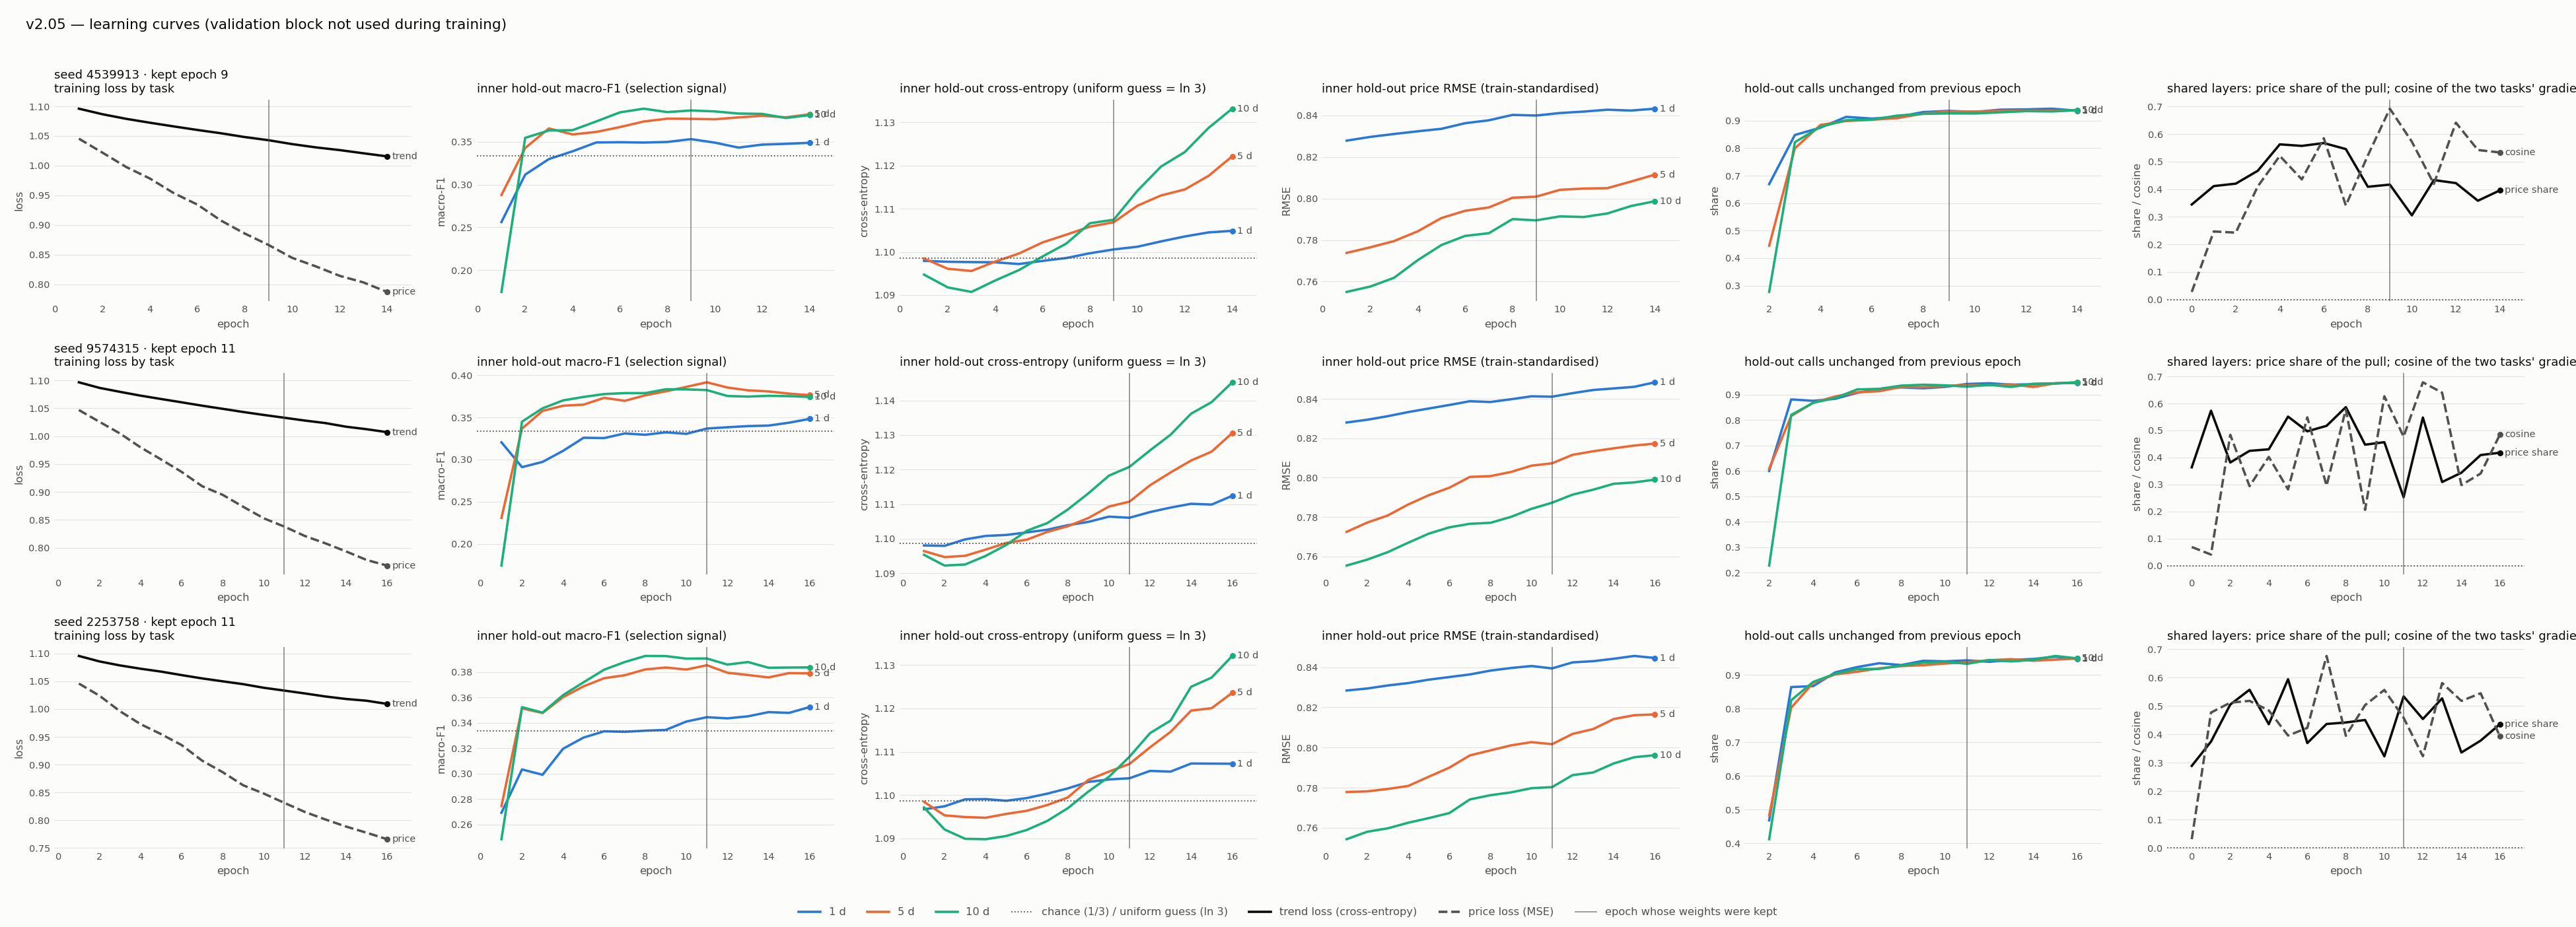

saved /content/drive/MyDrive/Senior/results/v2xx/A100/v2_05_calls.png


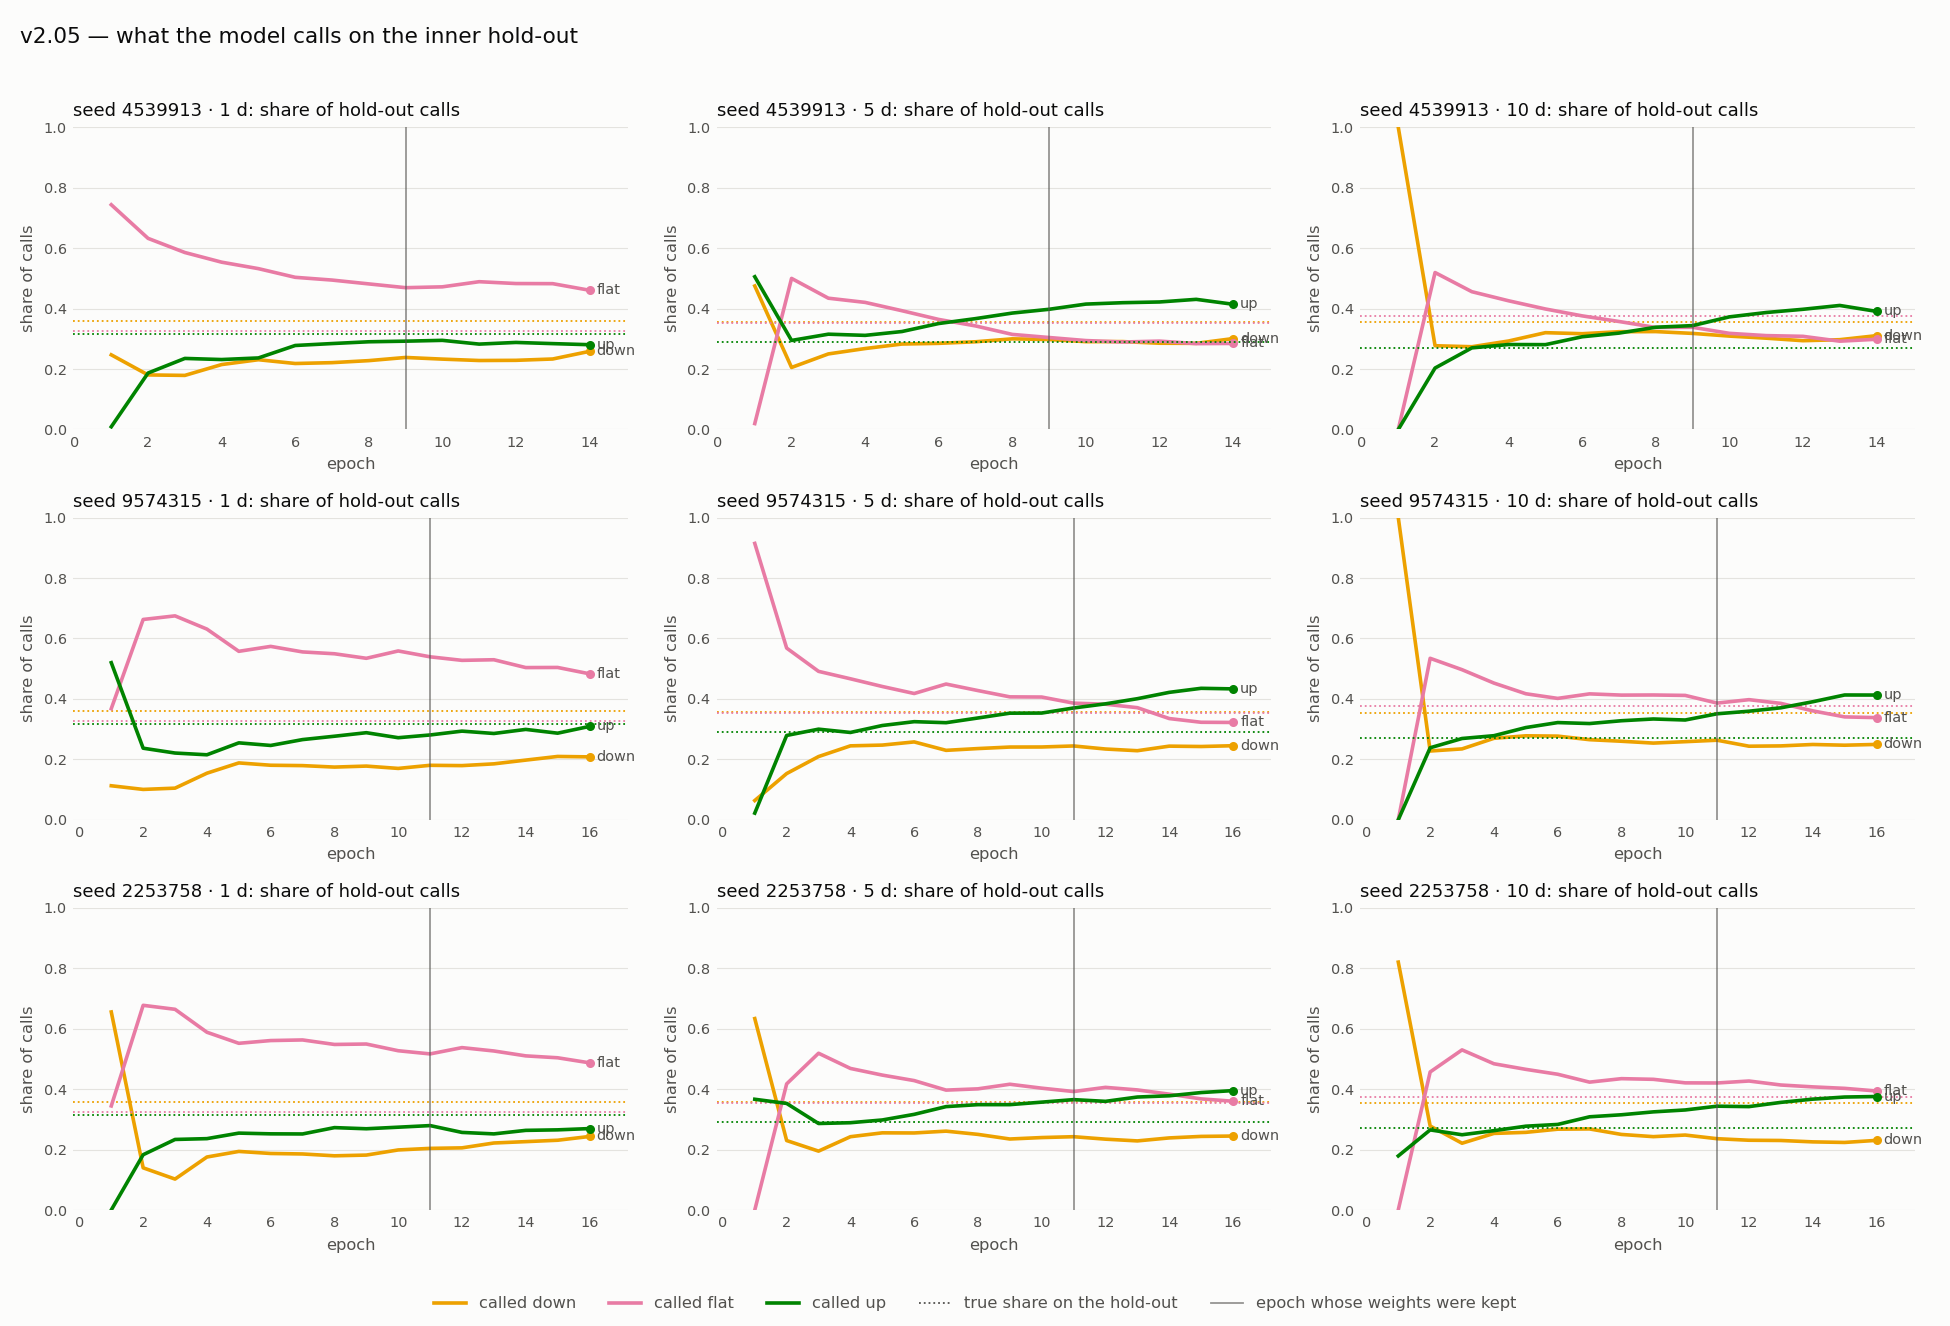

In [6]:
# 2. Summary beside v2.04 and the floors, the gradient diagnostic, and the learning curves
r = json.load(open(V205)); s, fl = r['summary']['model'], r['floors']
b = json.load(open(BASE_RUN))['summary']['model']
BAR = {'h1': 0.393, 'h5': 0.400, 'h10': 0.407}
print(f"{'':6}{'v2.05 F1':>18}{'v2.04':>8}{'bar':>7}{'continues':>11}{'reverses':>10}{'R2_OS':>10}{'v2.04 R2':>10}")
for h in ('h1', 'h5', 'h10'):
    m = s[h]
    print(f"{h:6}{m['macro_f1']['mean']:>11.4f} ± {m['macro_f1']['std']:.4f}{b[h]['macro_f1']['mean']:>8.4f}{BAR[h]:>7.3f}"
          f"{fl[h]['trend_continues']['macro_f1']:>11.3f}{fl[h]['trend_reverses']['macro_f1']:>10.3f}"
          f"{m['r2_os_vs_zero']['mean']:>+10.4f}{b[h]['r2_os_vs_zero']['mean']:>+10.4f}")
for x in r['runs']:
    g0, gk = x.get('grad_shared_before_training', {}), x['history'][x['best_epoch'] - 1].get('grad_shared', {})
    print('seed', x['seed'], 'epochs', x['epochs_run'], 'kept', x['best_epoch'], 'hold-out F1', x['best_inner_es_macro_f1'],
          '| price share of the shared pull: before training', g0.get('price_share_weighted'), 'at the kept epoch', gk.get('price_share_weighted'),
          '| cosine', g0.get('cosine'), '->', gk.get('cosine'), '| minutes', round(x['seconds'] / 60, 1))
from IPython.display import Image, display
import importlib, plot_v2xx_training as PT
for png in (PT.plot(Path(V205)), PT.plot_calls(Path(V205))):
    if png:
        print('saved', png); display(Image(filename=str(png)))

In [7]:
# 3. Post-hoc step for v2.05 (same script and settings as v2.03beta / v2.04): reproduction check, ts, blend (w on v2.05's
#    own inner hold-out), news blanked and placebo, on validation and 2026
common = ['--run-json', V205, '--fwd-inputs', FWD_INPUTS, '--out-dir', POST, '--label', 'v2.05 post-hoc']
for stage in ('prepare', 'predict', 'trees', 'analyze'):
    stream(['python', 'scripts/step0_v2_03beta.py', stage, *common])

2026 members: 54 symbols; with no frozen price history: ['MRDIYT', 'TFG', 'THAI']
reusing saved forward inputs in /content/drive/MyDrive/Senior/results/v2_05_posthoc/inputs (pass --refresh to fetch again)
forward price rows: 13107 after 2025-12-30, last day 2026-10-15, 191 trading days
breaks added (new tickers, or 2026 rows): {'BANPU': ['2026-01-05'], 'THAI': ['2021-04-16', '2025-08-04']}
large moves kept (|log r| 0.18-0.300), check against SET corporate actions: [{'symbol': 'BANPU', 'date': '2026-08-05', 'log_return': 0.2298}, {'symbol': 'JMART', 'date': '2026-05-15', 'log_return': 0.1982}, {'symbol': 'MRDIYT', 'date': '2026-06-30', 'log_return': 0.2661}, {'symbol': 'MRDIYT', 'date': '2026-07-01', 'log_return': -0.1989}, {'symbol': 'THAI', 'date': '2021-05-17', 'log_return': 0.26}, {'symbol': 'VGI', 'date': '2026-02-13', 'log_return': 0.2031}]
  note: 2026 splits fetched before the frozen events file was made (2026-09-25): [{'symbol': 'GLOBAL', 'date': 20260224, 'event': 'split', 'va

In [8]:
# 4. v2.05 vs v2.04 on the same rows, and the pre-registered adopt rule (trend up, price not worse, blanked held)
stream(['python', 'scripts/compare_v2xx_posthoc.py', '--base', BASE, '--new', POST, '--rule', 'trend_up_price_held',
        '--base-run', BASE_RUN, '--new-run', V205, '--out', f'{RES}/v2_05_vs_v2_04.json'])


v2.05 vs v2.04 (validation macro-F1, seed mean; blend w v2.05 [0.4, 0.9, 0.8], v2.04 [0.6, 0.9, 0.9])
                                 1 d     5 d    10 d    mean   new - base, 3-horizon mean (95% interval)
v2.04 news_on raw             0.3391  0.3692  0.3721  0.3601
v2.05 news_on raw             0.3423  0.3677  0.3680  0.3593   -0.0008 [-0.0056, 0.0029]
v2.04 news_on ts_blend        0.3591  0.3742  0.3734  0.3689
v2.05 news_on ts_blend        0.3655  0.3708  0.3708  0.3690   +0.0001 [-0.004, 0.0034]
v2.04 news_blanked raw        0.3404  0.3549  0.3489  0.3481
v2.05 news_blanked raw        0.3466  0.3543  0.3444  0.3484   +0.0003 [-0.0049, 0.0052]
v2.04 news_blanked ts_blend   0.3578  0.3587  0.3494  0.3553
v2.05 news_blanked ts_blend   0.3626  0.3567  0.3457  0.3550   -0.0003 [-0.0047, 0.0035]
v2.04 price R2_OS            -0.0325 -0.0319 -0.0386 -0.0343
v2.05 price R2_OS            -0.0317 -0.0509 -0.0683 -0.0503

ADOPT RULE trend_up_price_held: (a) news-on mean up: False; (b) price 

**Reading the result**
- **ADOPT RULE** (last block): (a) the news-on 3-horizon mean goes up, (b) price R²_OS doesn't get worse, and (c) news-blanked doesn't fall significantly. All are judged on the raw models.
- **Gradient diagnostic:** the price task's share of the pull on the shared layers. The plan assumes about half with weight 0.25 (about 80% at 1 : 1). The cosine shows whether the two tasks pull in the same direction (> 0) or against each other (< 0).
- **ts + blend** and **2026** are reported beside it, as for v2.04.
- Send the printout to Claude.